# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Boda-25/FlyRank-machine-learning/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions and reason codes

The queue ranks content items by the selected model's decline-risk score. It is designed to help an SEO analyst decide which pages deserve human review first.

Each item receives observable reason codes based on its available performance and content measurements.

- STALE_VISIBLE: an older page with meaningful search impressions.
- LOW_CTR: a page with enough impressions, a measurable search position, and low CTR.
- LOW_ENGAGEMENT: a page with enough sessions but low engagement or scroll rate.
- THIN_CONTENT: a relatively short page with measurable search visibility.
- POSITION_OPPORTUNITY: a page ranking between positions 10 and 50 with search impressions.
- INSUFFICIENT_EVIDENCE: not enough measurements to support a confident recommendation.
- MODEL_FLAG_ONLY: a high model score without another rule-based reason.

The model score is a prioritization signal, not proof that refreshing a page will improve its performance. Reason codes explain the observed context behind each suggested action.

In [5]:
# ============================================
# 1. IMPORT LIBRARIES
# ============================================

from pathlib import Path
import subprocess
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================
# 2. DOWNLOAD REPOSITORY
# ============================================

ROOT = Path("/content/FlyRank-machine-learning")

if not ROOT.exists():
    subprocess.run(
        [
            "git",
            "clone",
            "https://github.com/Boda-25/FlyRank-machine-learning.git",
            str(ROOT)
        ],
        check=True
    )
else:
    print("Repository already exists. Using existing copy.")


# ============================================
# 3. SET WORKING DIRECTORY
# ============================================

os.chdir(ROOT)

print("Repository root:", ROOT)
print("Current directory:", Path.cwd())


# ============================================
# 4. DEFINE FILE PATHS
# ============================================

FEATURE_PATH = ROOT / "data/processed/refresh_feature_vector.csv"
PRED_PATH = ROOT / "data/processed/model_predictions.csv"
RESULT_PATH = ROOT / "outputs/model_results.json"

OUT_DIR = ROOT / "work/outputs"
FIG_DIR = ROOT / "work/figures"

OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)


# ============================================
# 5. CHECK REQUIRED FILES
# ============================================

required_files = {
    "Feature dataset": FEATURE_PATH,
    "Model predictions": PRED_PATH,
    "Model results": RESULT_PATH
}

missing_files = []

for name, path in required_files.items():
    exists = path.exists()
    print(f"{name}: {'FOUND' if exists else 'NOT FOUND'}")
    print(f"Path: {path}\n")

    if not exists:
        missing_files.append(name)


if missing_files:
    raise FileNotFoundError(
        "Missing required files: "
        + ", ".join(missing_files)
        + "\nThe preprocessing/model training outputs may not exist "
          "in the repository copy yet."
    )


# ============================================
# 6. LOAD DATA
# ============================================

features = pd.read_csv(FEATURE_PATH)
predictions = pd.read_csv(PRED_PATH)

with open(RESULT_PATH, "r") as f:
    model_results = json.load(f)


# ============================================
# 7. INITIAL INSPECTION
# ============================================

print("=" * 60)
print("DATA LOADED SUCCESSFULLY")
print("=" * 60)

print("\nFeature dataset shape:", features.shape)
print("Prediction dataset shape:", predictions.shape)

print("\nFeature columns:")
print(features.columns.tolist())

print("\nPrediction columns:")
print(predictions.columns.tolist())

print("\nModel results:")
print(json.dumps(model_results, indent=2))

print("\nOutput directory:", OUT_DIR)
print("Figures directory:", FIG_DIR)

Repository already exists. Using existing copy.
Repository root: /content/FlyRank-machine-learning
Current directory: /content/FlyRank-machine-learning
Feature dataset: FOUND
Path: /content/FlyRank-machine-learning/data/processed/refresh_feature_vector.csv

Model predictions: FOUND
Path: /content/FlyRank-machine-learning/data/processed/model_predictions.csv

Model results: FOUND
Path: /content/FlyRank-machine-learning/outputs/model_results.json

DATA LOADED SUCCESSFULLY

Feature dataset shape: (30000, 52)
Prediction dataset shape: (30000, 9)

Feature columns:
['content_id', 'client_id', 'search_volume', 'competition', 'competition_level', 'cpc', 'content_type', 'main_intent', 'word_count', 'char_count', 'provider_used', 'model_used', 'impressions_90d', 'clicks_90d', 'pageviews_90d', 'sessions_90d', 'users_90d', 'engaged_sessions_90d', 'ai_sessions_90d', 'scroll_events_90d', 'days_with_impressions', 'days_with_sessions', 'impressions_last_30d', 'clicks_last_30d', 'sessions_last_30d', 'i

In [3]:

# ============================================
# GENERATE THE MISSING PROJECT OUTPUTS
# ============================================

from pathlib import Path
import subprocess
import sys
import os

ROOT = Path("/content/FlyRank-machine-learning")
os.chdir(ROOT)

# Check the project files
print("Project files:")
for path in [
    ROOT / "scripts/run_all.py",
    ROOT / "requirements.txt",
    ROOT / "data/raw/content_refresh_anonymized.csv"
]:
    print(path.relative_to(ROOT), "->", path.exists())

# Make sure the pipeline script exists
PIPELINE = ROOT / "scripts/run_all.py"

if not PIPELINE.exists():
    raise FileNotFoundError(
        "scripts/run_all.py was not found. "
        "We need to inspect the repository scripts."
    )

# Install dependencies
print("\nInstalling requirements...")
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-r", "requirements.txt"],
    check=True
)

# Run the project pipeline
print("\nRunning project pipeline...")
subprocess.run(
    [sys.executable, str(PIPELINE)],
    cwd=ROOT,
    check=True
)

print("\nPipeline execution finished.")

# Search for generated files
print("\nSearching for generated outputs...")

for pattern in [
    "refresh_feature_vector.csv",
    "model_predictions.csv",
    "model_results.json"
]:
    matches = list(ROOT.rglob(pattern))
    print(f"\n{pattern}:")
    if matches:
        for match in matches:
            print(match)
    else:
        print("NOT FOUND")


Project files:
scripts/run_all.py -> True
requirements.txt -> True
data/raw/content_refresh_anonymized.csv -> True

Installing requirements...

Running project pipeline...

Pipeline execution finished.

Searching for generated outputs...

refresh_feature_vector.csv:
/content/FlyRank-machine-learning/data/processed/refresh_feature_vector.csv

model_predictions.csv:
/content/FlyRank-machine-learning/data/processed/model_predictions.csv

model_results.json:
/content/FlyRank-machine-learning/outputs/model_results.json


## 2.  Intended use and limits

This playbook is intended for SEO analysts and content editors as a non-production decision-support tool.

It helps prioritize pages for review, identify possible content issues, and organize editorial workload.

The model was trained to identify a decline proxy from the available snapshot. Its score is not the probability that a content refresh will succeed.

The data is observational. It cannot prove that updating a page, changing a title, or expanding content will cause better search performance.

Recommendations may become outdated when search demand, competition, content intent, or measurement systems change. All suggested actions require human review.

In [7]:
import numpy as np
import pandas as pd

# ============================================
# GENERATE RANKED QUEUE
# ============================================

# Join predictions to the prepared feature data.
queue = features.merge(
    predictions[
        ["content_id", "best_model_probability", "best_model_name"]
    ],
    on="content_id",
    how="inner",
    validate="one_to_one"
)

numeric_cols = [
    "impressions_90d", "sessions_90d", "ctr",
    "avg_position", "engagement_rate", "scroll_rate",
    "word_count", "days_since_last_update",
    "content_age_days", "impressions_last_30d",
    "impressions_prev_30d", "best_model_probability"
]

for col in numeric_cols:
    queue[col] = pd.to_numeric(queue[col], errors="coerce")

queue = queue.replace([np.inf, -np.inf], np.nan)
queue = queue.dropna(subset=["best_model_probability"]).copy()
queue["best_model_probability"] = queue[
    "best_model_probability"
].clip(0, 1)

# Reason codes
def get_reason_codes(row):
    reasons = []
    if (
        row["days_since_last_update"] >= 180
        and row["impressions_90d"] >= 500
    ):
        reasons.append("STALE_VISIBLE")
    if (
        row["impressions_90d"] >= 500
        and 0 < row["avg_position"] <= 20
        and row["ctr"] < 0.5
    ):
        reasons.append("LOW_CTR")
    if (
        row["sessions_90d"] >= 30
        and (
            row["engagement_rate"] < 30
            or row["scroll_rate"] < 30
        )
    ):
        reasons.append("LOW_ENGAGEMENT")
    if (
        pd.notna(row["word_count"])
        and 0 < row["word_count"] < 1200
        and row["impressions_90d"] >= 250
    ):
        reasons.append("THIN_CONTENT")
    if (
        row["impressions_90d"] >= 100
        and 10 < row["avg_position"] <= 50
    ):
        reasons.append("POSITION_OPPORTUNITY")
    if (
        row["impressions_90d"] < 100
        or row["sessions_90d"] < 10
    ):
        reasons.append("INSUFFICIENT_EVIDENCE")
    return reasons if reasons else ["MODEL_FLAG_ONLY"]

queue["reason_codes"] = queue.apply(get_reason_codes, axis=1)
queue["reason_codes_text"] = queue["reason_codes"].apply(
    lambda x: " | ".join(x)
)

# Archetypes
def get_archetype(row):
    intent = str(row["main_intent"]).lower()
    if intent == "commercial":
        return "COMMERCIAL"
    if intent == "transactional":
        return "TRANSACTIONAL"
    if intent == "informational":
        return "INFORMATIONAL"
    return "OTHER"

queue["archetype"] = queue.apply(get_archetype, axis=1)

ARCHETYPE_ACTION = {
    "COMMERCIAL": "Review comparisons, product details and decision support",
    "TRANSACTIONAL": "Review conversion path and page clarity",
    "INFORMATIONAL": "Review freshness, completeness and search intent",
    "OTHER": "Request manual content classification"
}
queue["archetype_action"] = queue["archetype"].map(ARCHETYPE_ACTION)

# Actions
ACTION_MAP = {
    "STALE_VISIBLE": "CONTENT_REFRESH_REVIEW",
    "LOW_CTR": "TITLE_SNIPPET_REVIEW",
    "LOW_ENGAGEMENT": "CONTENT_QUALITY_UX_REVIEW",
    "THIN_CONTENT": "CONTENT_DEPTH_REVIEW",
    "POSITION_OPPORTUNITY": "SEARCH_INTENT_GAP_REVIEW",
    "INSUFFICIENT_EVIDENCE": "MEASUREMENT_CHECK",
    "MODEL_FLAG_ONLY": "GENERAL_EDITORIAL_REVIEW"
}

def choose_action(reasons):
    priority = [
        "MEASUREMENT_CHECK",
        "TITLE_SNIPPET_REVIEW",
        "CONTENT_QUALITY_UX_REVIEW",
        "CONTENT_REFRESH_REVIEW",
        "CONTENT_DEPTH_REVIEW",
        "SEARCH_INTENT_GAP_REVIEW",
        "GENERAL_EDITORIAL_REVIEW"
    ]
    possible = [ACTION_MAP[r] for r in reasons]
    return next((a for a in priority if a in possible), possible[0])

queue["recommended_action"] = queue["reason_codes"].apply(choose_action)

# Effort and Value Tiers
queue["effort_tier"] = queue["recommended_action"].map({
    "MEASUREMENT_CHECK": "LOW",
    "TITLE_SNIPPET_REVIEW": "LOW",
    "CONTENT_REFRESH_REVIEW": "MEDIUM",
    "SEARCH_INTENT_GAP_REVIEW": "MEDIUM",
    "CONTENT_QUALITY_UX_REVIEW": "HIGH",
    "CONTENT_DEPTH_REVIEW": "HIGH",
    "GENERAL_EDITORIAL_REVIEW": "MEDIUM"
})

queue["value_tier"] = pd.cut(
    queue["impressions_90d"],
    bins=[-1, 99, 499, 2999, np.inf],
    labels=["LOW", "MODERATE", "HIGH", "VERY_HIGH"]
).astype(str)

# Sort and Rank
queue = queue.sort_values(
    "best_model_probability",
    ascending=False
).reset_index(drop=True)
queue.insert(0, "priority_rank", range(1, len(queue) + 1))

# ============================================
# BASIC INTENDED-USE AND DATA-SCOPE CHECKS
# ============================================
print("Intended users: SEO analysts and content editors")
print("Use: human-reviewed prioritization")
print("Production automation: NOT allowed")

print("\nQueue coverage")
print("Prepared feature rows:", len(features))
print("Prediction rows:", len(predictions))
print("Matched queue rows:", len(queue))
print("Unmatched feature rows:", len(features) - len(queue))

assert len(queue) > 0, "The ranked queue is empty."
assert queue["best_model_probability"].between(0, 1).all()

print("\nModel:", model_results["best_model"]["name"])
print("Target:", model_results["target"])
print("Split strategy:", model_results["split_strategy"])

Intended users: SEO analysts and content editors
Use: human-reviewed prioritization
Production automation: NOT allowed

Queue coverage
Prepared feature rows: 30000
Prediction rows: 30000
Matched queue rows: 30000
Unmatched feature rows: 0

Model: random_forest
Target: is_declining_label
Split strategy: client_holdout


## 3. Human review rules

Before acting on a recommendation, a qualified editor must:

1. Confirm that the page measurements are current.
2. Check the page's actual search intent and search results context.
3. Review factual accuracy and content usefulness.
4. Consider seasonality, competition and tracking changes.
5. Decide whether to accept, reject, defer or request more evidence.
6. Record the decision and the reason.

### No-go list

The system must never automatically:

- Publish or rewrite content.
- Delete, redirect or canonicalize pages.
- Change prices, legal, medical or financial claims.
- Add facts that have not been verified.
- Make client-facing promises about traffic or ranking gains.
- Treat a high score as proof of business value.

The model prioritizes review only. A human owns every final editorial decision.

In [8]:
# Human-review audit
review_fields = [
    "priority_rank",
    "recommended_action",
    "reason_codes_text",
    "best_model_probability",
    "effort_tier",
    "value_tier"
]

assert all(col in queue.columns for col in review_fields)

review_sample = queue[review_fields].head(10).copy()
review_sample["human_decision"] = "PENDING_REVIEW"

display(review_sample)

print("Human approval required for every recommended action.")
print("Automatic publishing/deletion/redirects: prohibited.")

,priority_rank,recommended_action,reason_codes_text,best_model_probability,effort_tier,value_tier,human_decision
0,1,CONTENT_QUALITY_UX_REVIEW,LOW_ENGAGEMENT | POSITION_OPPORTUNITY,0.851816,HIGH,VERY_HIGH,PENDING_REVIEW
1,2,MEASUREMENT_CHECK,INSUFFICIENT_EVIDENCE,0.851108,LOW,MODERATE,PENDING_REVIEW
2,3,MEASUREMENT_CHECK,LOW_CTR | POSITION_OPPORTUNITY | INSUFFICIENT_...,0.849842,LOW,HIGH,PENDING_REVIEW
3,4,SEARCH_INTENT_GAP_REVIEW,POSITION_OPPORTUNITY,0.848932,MEDIUM,HIGH,PENDING_REVIEW
4,5,TITLE_SNIPPET_REVIEW,LOW_CTR,0.848494,LOW,HIGH,PENDING_REVIEW
5,6,TITLE_SNIPPET_REVIEW,LOW_CTR | LOW_ENGAGEMENT,0.848402,LOW,HIGH,PENDING_REVIEW
6,7,CONTENT_QUALITY_UX_REVIEW,LOW_ENGAGEMENT | POSITION_OPPORTUNITY,0.847695,HIGH,VERY_HIGH,PENDING_REVIEW
7,8,CONTENT_QUALITY_UX_REVIEW,LOW_ENGAGEMENT | POSITION_OPPORTUNITY,0.847492,HIGH,HIGH,PENDING_REVIEW
8,9,CONTENT_QUALITY_UX_REVIEW,LOW_ENGAGEMENT | POSITION_OPPORTUNITY,0.847401,HIGH,VERY_HIGH,PENDING_REVIEW
9,10,CONTENT_QUALITY_UX_REVIEW,LOW_ENGAGEMENT | POSITION_OPPORTUNITY,0.847066,HIGH,VERY_HIGH,PENDING_REVIEW


Human approval required for every recommended action.
Automatic publishing/deletion/redirects: prohibited.


## 4.  Monitoring and retraining triggers

Review this playbook regularly using a new comparable data snapshot.

Monitor:
- Changes in the distribution of model scores.
- Changes in content archetypes and recommended actions.
- Missingness in important measurements.
- Ranking stability between snapshots.
- Human acceptance and rejection rates.
- Precision@K on a newly validated dataset with an independently defined target.

Revisit or retrain the model when the data schema changes, the input distribution shifts, model performance declines on a comparable holdout, or editorial reviewers repeatedly reject recommendations.

These are proposed monitoring rules. They do not imply that drift or model failure has already occurred.

In [9]:
# Current snapshot monitoring summary
monitoring = {
    "rows": int(len(queue)),
    "missing_score": int(queue["best_model_probability"].isna().sum()),
    "score_mean": float(queue["best_model_probability"].mean()),
    "score_median": float(queue["best_model_probability"].median()),
    "score_std": float(queue["best_model_probability"].std()),
    "action_distribution": queue["recommended_action"].value_counts().to_dict(),
    "archetype_distribution": queue["archetype"].value_counts().to_dict()
}

print(json.dumps(monitoring, indent=2))

# These checks describe this snapshot only.
assert monitoring["rows"] > 0
assert monitoring["missing_score"] == 0

{
  "rows": 30000,
  "missing_score": 0,
  "score_mean": 0.5089249578150314,
  "score_median": 0.5380977802832047,
  "score_std": 0.19103352385583305,
  "action_distribution": {
    "MEASUREMENT_CHECK": 17199,
    "TITLE_SNIPPET_REVIEW": 6578,
    "CONTENT_QUALITY_UX_REVIEW": 3650,
    "SEARCH_INTENT_GAP_REVIEW": 1875,
    "GENERAL_EDITORIAL_REVIEW": 681,
    "CONTENT_DEPTH_REVIEW": 16,
    "CONTENT_REFRESH_REVIEW": 1
  },
  "archetype_distribution": {
    "INFORMATIONAL": 17235,
    "TRANSACTIONAL": 5733,
    "COMMERCIAL": 4612,
    "OTHER": 2420
  }
}


## 5.  Exports and decay insight

The notebook exports a ranked action queue, action-distribution figures, archetype figures and a descriptive freshness summary.

The decay analysis compares recent impressions with previous-period impressions across groups of content update recency.

This is an observational comparison, not evidence that refreshing older content causes impressions to increase.

The exported queue is intended for editorial review and for use in the recommendations section of the research paper.

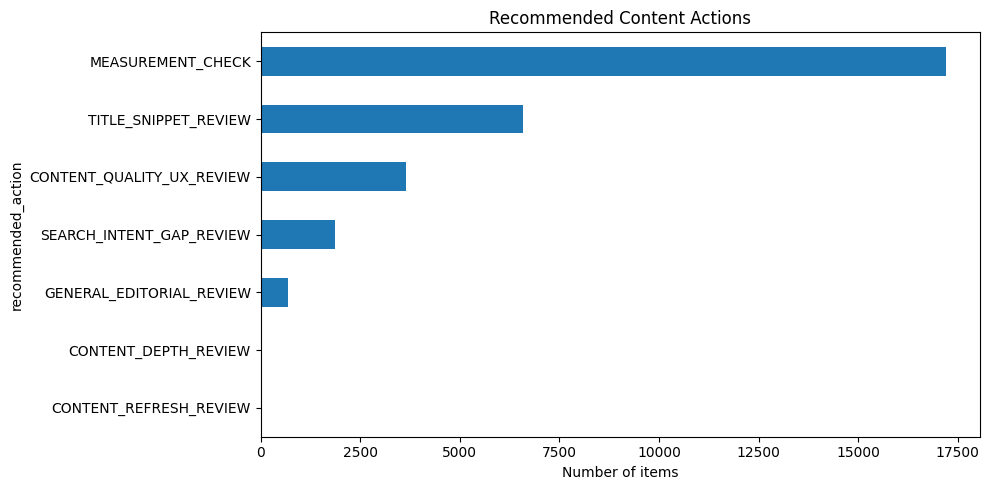

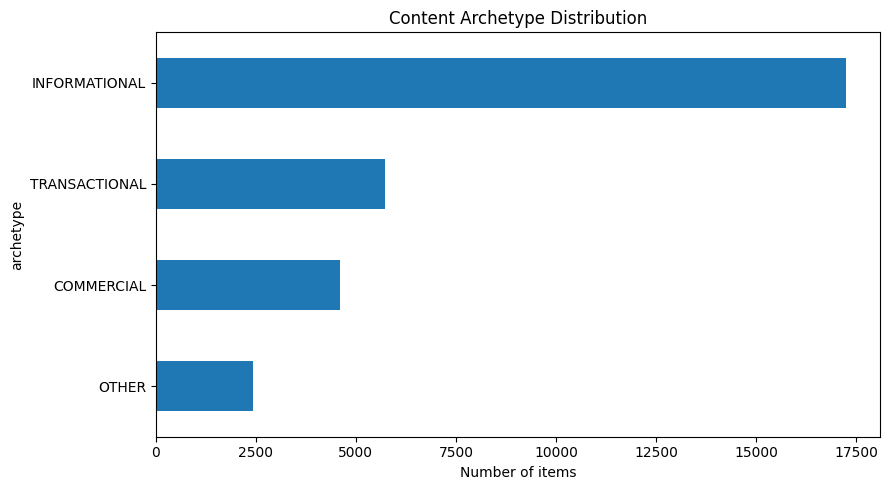

,freshness_group,content_items,median_impressions_ratio
0,0-30 days,17454,0.666667
1,31-90 days,167,0.615385
2,91-180 days,8858,0.656060
3,181+ days,133,0.554572


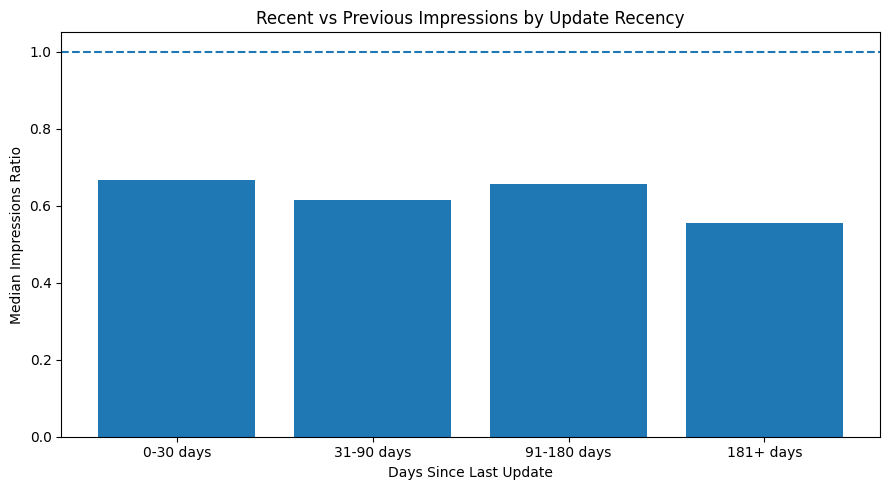

Successfully generated:
work/outputs/w07_ranked_action_queue.csv
work/outputs/w07_decay_freshness_summary.csv
work/outputs/w07_action_playbook_metrics.json
work/figures/w07_action_distribution.png
work/figures/w07_archetype_distribution.png
work/figures/w07_decay_freshness_insight.png


In [10]:
# Export queue without client identifiers, URLs or private queries.
export_columns = [
    "priority_rank",
    "content_id",
    "best_model_name",
    "best_model_probability",
    "archetype",
    "archetype_action",
    "recommended_action",
    "reason_codes_text",
    "effort_tier",
    "value_tier",
    "impressions_90d",
    "sessions_90d",
    "ctr",
    "avg_position",
    "engagement_rate",
    "scroll_rate",
    "days_since_last_update"
]

queue_path = OUT_DIR / "w07_ranked_action_queue.csv"
queue[export_columns].to_csv(queue_path, index=False)

# Figure 1: Recommended actions
action_counts = queue["recommended_action"].value_counts()

plt.figure(figsize=(10, 5))
action_counts.sort_values().plot(kind="barh")
plt.title("Recommended Content Actions")
plt.xlabel("Number of items")
plt.tight_layout()
plt.savefig(FIG_DIR / "w07_action_distribution.png", dpi=160)
plt.show()
plt.close()

# Figure 2: Content archetypes
archetype_counts = queue["archetype"].value_counts()

plt.figure(figsize=(9, 5))
archetype_counts.sort_values().plot(kind="barh")
plt.title("Content Archetype Distribution")
plt.xlabel("Number of items")
plt.tight_layout()
plt.savefig(FIG_DIR / "w07_archetype_distribution.png", dpi=160)
plt.show()
plt.close()

# Descriptive freshness / decay analysis
decay = features.copy()

decay["days_since_last_update"] = pd.to_numeric(
    decay["days_since_last_update"], errors="coerce"
)
decay["impressions_last_30d"] = pd.to_numeric(
    decay["impressions_last_30d"], errors="coerce"
)
decay["impressions_prev_30d"] = pd.to_numeric(
    decay["impressions_prev_30d"], errors="coerce"
)

decay = decay.dropna(subset=[
    "days_since_last_update",
    "impressions_last_30d",
    "impressions_prev_30d"
]).copy()

decay = decay[decay["impressions_prev_30d"] > 0].copy()

decay["recent_previous_ratio"] = (
    decay["impressions_last_30d"] /
    decay["impressions_prev_30d"]
)

decay["freshness_group"] = pd.cut(
    decay["days_since_last_update"],
    bins=[-1, 30, 90, 180, np.inf],
    labels=["0-30 days", "31-90 days", "91-180 days", "181+ days"]
)

decay_summary = (
    decay.groupby("freshness_group", observed=False)
    .agg(
        content_items=("content_id", "count"),
        median_impressions_ratio=("recent_previous_ratio", "median")
    )
    .reset_index()
)

display(decay_summary)

decay_summary.to_csv(
    OUT_DIR / "w07_decay_freshness_summary.csv",
    index=False
)

# Figure 3: Freshness comparison
plt.figure(figsize=(9, 5))
plt.bar(
    decay_summary["freshness_group"].astype(str),
    decay_summary["median_impressions_ratio"]
)
plt.axhline(1, linestyle="--")
plt.title("Recent vs Previous Impressions by Update Recency")
plt.xlabel("Days Since Last Update")
plt.ylabel("Median Impressions Ratio")
plt.tight_layout()
plt.savefig(FIG_DIR / "w07_decay_freshness_insight.png", dpi=160)
plt.show()
plt.close()

# Paper-ready metrics JSON
paper_metrics = {
    "notebook": "ML-10 Content Action Playbook",
    "rows_in_queue": int(len(queue)),
    "selected_model": str(model_results["best_model"]["name"]),
    "ranking_score": "best_model_probability",
    "target": str(model_results["target"]),
    "split_strategy": str(model_results["split_strategy"]),
    "top_50_action_counts": (
        queue.head(50)["recommended_action"].value_counts().to_dict()
    ),
    "reason_code_counts": (
        queue["reason_codes_text"]
        .str.split(" | ", regex=False)
        .explode()
        .value_counts()
        .to_dict()
    ),
    "archetype_counts": queue["archetype"].value_counts().to_dict(),
    "human_review_required": True,
    "production_automation": False,
    "decay_analysis": "Observational, not causal"
}

metrics_path = OUT_DIR / "w07_action_playbook_metrics.json"

with open(metrics_path, "w") as f:
    json.dump(paper_metrics, f, indent=2)

print("Successfully generated:")
for path in [
    queue_path,
    OUT_DIR / "w07_decay_freshness_summary.csv",
    metrics_path,
    FIG_DIR / "w07_action_distribution.png",
    FIG_DIR / "w07_archetype_distribution.png",
    FIG_DIR / "w07_decay_freshness_insight.png"
]:
    print(path.relative_to(ROOT))

## Self-check

- [ ] Ranked actions and reason codes are documented.
- [ ] Archetype-to-action mapping is included.
- [ ] Decay/freshness insight is included and described honestly.
- [ ] Intended use and limitations are explained.
- [ ] Human review rules and no-go cases are explicit.
- [ ] Cost/effort and value tiers are explained as proxies.
- [ ] Monitoring and retraining triggers are documented.
- [ ] Queue and figures are exported successfully.
- [ ] Metrics JSON is saved under work/outputs/.
- [ ] No client names, URLs or private queries are included.
- [ ] Notebook runs from top to bottom without errors.
- [ ] Notebook and required figures/metrics are committed to my repository.